# A latent text-to-image pipeline end to end

Booster LEAP, Diffusion Models, topic 5. You train a small autoencoder on photographs, then build and train a complete toy latent text-to-image pipeline (tokenizer, text encoder, autoencoder, U-Net, scheduler, guidance) on digit images, measure it, and compare schedulers.

<h1 style="color:#b45309">&#9888; First: File &rarr; Save a copy in Drive</h1>

<span style="font-size:20px">This notebook is read-only. Make your own copy now, then work in the copy (no GitHub login needed).</span>

**How to use this notebook:** run the cells from top to bottom (Runtime, Run all, or Shift+Enter on each cell). It needs no GPU. It loads three real photographs from our public GitHub repository (an internet connection is needed, Colab has one). Photos: china.jpg and flower.jpg are scikit-learn sample images (Flickr users danielbuechele and vultilion, CC BY 2.0); grace_hopper.jpg is a U.S. Navy photograph, public domain. Change one thing at a time and run again; the last cell tells you what to try, including your own photo.

**What you need to know first:** nothing about diffusion. Two ideas help: a *Gaussian* is the bell-curve random number (`np.random.standard_normal`), and a *pixel value* is a number from 0 to 255. Everything else is explained where it appears.

## 1. Part A: an autoencoder on photographs

Lesson 2 trains this on the whole test photo and prints the numbers. Here it is cell by cell, with pictures. The autoencoder squeezes every 4 x 4 block of colour numbers (48 numbers) into a few latent numbers and redraws the block.

In [ ]:
import io, math, urllib.request
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
print("torch", torch.__version__, "- runs on the CPU, no GPU needed")

BASE = "https://raw.githubusercontent.com/boosterleap/booster-leap-notebooks/main/diffusion-models/images/"
FILES = {"china": "china.jpg", "flower": "flower.jpg", "hopper": "grace_hopper.jpg"}
def load_photo(name):
    return Image.open(io.BytesIO(urllib.request.urlopen(BASE + FILES[name]).read())).convert("RGB")
def to_tensor(img):                                       # picture -> tensor (3, h, w) with values -1 .. 1
    return torch.tensor(np.asarray(img, dtype=np.float32) / 127.5 - 1).permute(2, 0, 1)
def to_picture(t):
    return ((t.permute(1, 2, 0).clamp(-1, 1).numpy() + 1) / 2)
def psnr(a, b):
    return 10 * math.log10(4 / F.mse_loss(a, b).item())

# training photos: the flower and the portrait. Test photo: the pagoda, which the autoencoder never sees.
# Your own photo (optional): remove the # signs, run the cell, choose a file; it replaces the test photo.
# from google.colab import files
# test_img = Image.open(next(iter(files.upload()))).convert("RGB").resize((192, 128), Image.LANCZOS)
test_img = load_photo("china").resize((192, 128), Image.LANCZOS)
train = [to_tensor(load_photo("flower").resize((300, 198), Image.LANCZOS)), to_tensor(load_photo("hopper").resize((240, 240), Image.LANCZOS))]
china = to_tensor(test_img)
print("training pictures:", [tuple(t.shape) for t in train], " test picture:", tuple(china.shape))

torch 2.14.0+cpu - runs on the CPU, no GPU needed
training pictures: [(3, 198, 300), (3, 240, 240)]  test picture: (3, 128, 192)


In [ ]:
def crops(n, p=32):                                       # random 32 x 32 crops of the training photos
    out = []
    for _ in range(n):
        im = train[torch.randint(0, len(train), (1,)).item()]
        y, x = torch.randint(0, im.shape[1] - p + 1, (1,)).item(), torch.randint(0, im.shape[2] - p + 1, (1,)).item()
        out.append(im[:, y:y + p, x:x + p])
    return torch.stack(out)

class AE(nn.Module):                                      # downsampling factor 4: two stride-2 convolutions down, two transposed ones up
    def __init__(self, c, w=64):
        super().__init__()
        self.enc = nn.Sequential(nn.Conv2d(3, w, 3, padding=1), nn.SiLU(), nn.Conv2d(w, w, 4, 2, 1), nn.SiLU(), nn.Conv2d(w, w, 4, 2, 1), nn.SiLU(), nn.Conv2d(w, c, 3, padding=1))
        self.dec = nn.Sequential(nn.Conv2d(c, w, 3, padding=1), nn.SiLU(), nn.ConvTranspose2d(w, w, 4, 2, 1), nn.SiLU(), nn.ConvTranspose2d(w, w, 4, 2, 1), nn.SiLU(), nn.Conv2d(w, 3, 3, padding=1))
    def forward(self, x):
        return self.dec(self.enc(x))

C = 4                                                     # latent channels: 4 numbers per 4 x 4 block = 12 times fewer numbers
torch.manual_seed(0)
ae = AE(C)
opt = torch.optim.Adam(ae.parameters(), 2e-3)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, 2000)
for step in range(2000):                                  # train to copy photo crops through the bottleneck
    x = crops(16)
    loss = F.mse_loss(ae(x), x)
    opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    if step % 500 == 499:
        print("update", step + 1, "loss", round(loss.item(), 4))

update 500 loss 0.0065
update 1000 loss 0.0075
update 1500 loss 0.0089
update 2000 loss 0.0131


### How good is the compression?

Two baselines: the best **linear** code (PCA) with the same number of latent numbers, and simply shrinking the photo and enlarging it again. The autoencoder is tested on a photo it has not seen.

the photo has 73728 numbers; its latent has 6144  ( 12 times fewer )
spread of the latent values: 3.438 -> scale factor 1 / spread = 0.291 (diffusion would multiply the latents by this)


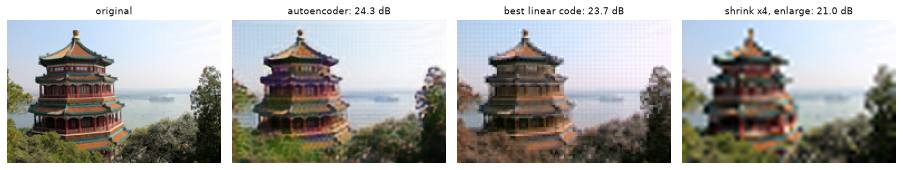

In [ ]:
def blocks(im):                                           # 4 x 4 blocks of 3 colours = 48 numbers per block
    return im.unfold(1, 4, 4).unfold(2, 4, 4).permute(1, 2, 0, 3, 4).reshape(-1, 48)
tr = torch.cat([blocks(t) for t in train])
mu = tr.mean(0)
Vt = torch.linalg.svd(tr - mu, full_matrices=False).Vh   # the best LINEAR code (PCA) from the training photos
H, W = china.shape[1:]
bt = blocks(china)
pca = (((bt - mu) @ Vt[:C].T) @ Vt[:C] + mu).reshape(H // 4, W // 4, 3, 4, 4).permute(2, 0, 3, 1, 4).reshape(3, H, W)
with torch.no_grad():
    z = ae.enc(china[None])
    rec = ae(china[None]).clamp(-1, 1)[0]
small = F.interpolate(china[None], scale_factor=1 / 4, mode="bicubic", align_corners=False)
shrunk = F.interpolate(small, scale_factor=4, mode="bicubic", align_corners=False).clamp(-1, 1)[0]
fig, ax = plt.subplots(1, 4, figsize=(13, 2.6))
for a, im, title in zip(ax, [china, rec, pca, shrunk], ["original", f"autoencoder: {psnr(rec, china):.1f} dB", f"best linear code: {psnr(pca.clamp(-1, 1), china):.1f} dB", f"shrink x4, enlarge: {psnr(shrunk, china):.1f} dB"]):
    a.imshow(to_picture(im)); a.axis("off"); a.set_title(title, fontsize=9)
plt.tight_layout(); plt.show()
print("the photo has", china.numel(), "numbers; its latent has", z.numel(), " (", round(china.numel() / z.numel()), "times fewer )")
print("spread of the latent values:", round(z.std().item(), 3), "-> scale factor 1 / spread =", round(1 / z.std().item(), 3), "(diffusion would multiply the latents by this)")

each latent channel is a 'picture' of (32, 48) positions: this is what a diffusion model would add noise to and denoise.


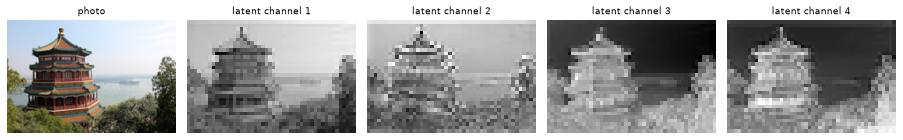

In [ ]:
fig, ax = plt.subplots(1, C + 1, figsize=(13, 2.4))
ax[0].imshow(to_picture(china)); ax[0].axis("off"); ax[0].set_title("photo", fontsize=9)
for k in range(C):
    ax[k + 1].imshow(z[0, k].numpy(), cmap="gray"); ax[k + 1].axis("off"); ax[k + 1].set_title(f"latent channel {k + 1}", fontsize=9)
plt.tight_layout(); plt.show()
print("each latent channel is a 'picture' of", tuple(z.shape[2:]), "positions: this is what a diffusion model would add noise to and denoise.")

## 2. Part B: a toy latent text-to-image pipeline on digits

Now the whole recipe of lessons 3 to 7 on 8 x 8 digit images, with the real diffusers classes built small: a tokenizer and a text encoder, an autoencoder (diffusers `AutoencoderKL`), a U-Net with cross-attention (`UNet2DConditionModel`) and a scheduler. Everything is a toy trained on a CPU in minutes; it is not Stable Diffusion and it does not use any pretrained weights. A separate classifier, the 'judge', measures the pictures.

In [ ]:
import math, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from diffusers import AutoencoderKL, UNet2DConditionModel, DDIMScheduler

torch.manual_seed(0)
d = load_digits()
X = torch.tensor(d.images, dtype=torch.float32)[:, None] / 16 * 2 - 1            # 1797 digits, 1 channel, 8 x 8, values -1 .. 1
Y = torch.tensor(d.target)
train_x, test_x, train_y, test_y = X[:1500], X[1500:], Y[:1500], Y[1500:]
judge = LogisticRegression(max_iter=2000).fit(train_x.flatten(1).numpy(), train_y.numpy())   # a separate classifier that only judges generated digits
print("data", tuple(X.shape), " the judge recognises", f"{100 * judge.score(test_x.flatten(1).numpy(), test_y.numpy()):.1f}% of real test digits")

# ---- the text side: a toy tokenizer and a tiny text encoder (trained together with the U-Net; a real system uses a big frozen encoder)
VOC = ["<pad>", "<bos>", "<eos>", "a", "drawing", "of", "the", "digit", "zero", "one", "two", "three", "four", "five", "six", "seven", "eight", "nine"]
W2I = {w: i for i, w in enumerate(VOC)}
PROMPTS = ["a drawing of the digit " + n for n in VOC[8:]]

def tokenize(prompts, n=8):                                # words -> ids, padded to 8 positions
    out = []
    for p in prompts:
        ids = [1] + [W2I[w] for w in p.split()] + [2]
        out.append(ids + [0] * (n - len(ids)))
    return torch.tensor(out)

class TextEncoder(nn.Module):                              # token ids (b, 8) -> one vector of 16 numbers per token (b, 8, 16)
    def __init__(self, d=16):
        super().__init__()
        self.emb = nn.Embedding(len(VOC), d)
        self.pos = nn.Parameter(torch.randn(8, d) * 0.02)
        self.layer = nn.TransformerEncoderLayer(d, 2, 32, batch_first=True, dropout=0.0)
    def forward(self, ids):
        return self.layer(self.emb(ids) + self.pos, src_key_padding_mask=(ids == 0))

# ---- the picture side: an autoencoder and a denoising U-Net, both from diffusers, built small
def make_vae(latent_channels=2):                           # 8 x 8 x 1 -> latent_channels x 4 x 4 (downsampling factor 2)
    return AutoencoderKL(in_channels=1, out_channels=1, down_block_types=("DownEncoderBlock2D",) * 2, up_block_types=("UpDecoderBlock2D",) * 2,
                         block_out_channels=(16, 32), layers_per_block=1, latent_channels=latent_channels, norm_num_groups=4, sample_size=8)

def make_unet(channels, size):                             # works on a (channels, size, size) grid; the prompt enters through cross-attention (width 16)
    return UNet2DConditionModel(sample_size=size, in_channels=channels, out_channels=channels,
                                down_block_types=("CrossAttnDownBlock2D", "DownBlock2D"), up_block_types=("UpBlock2D", "CrossAttnUpBlock2D"),
                                block_out_channels=(32, 64), layers_per_block=1, cross_attention_dim=16, attention_head_dim=8, norm_num_groups=8)

def count(m):
    return sum(p.numel() for p in m.parameters())

# the noise schedule is OURS (topics 2 and 3): linear betas 1e-4 .. 0.02, 1000 steps, the network predicts the noise
SCHED_CFG = dict(num_train_timesteps=1000, beta_start=1e-4, beta_end=0.02, beta_schedule="linear", clip_sample=False, prediction_type="epsilon")

import matplotlib.pyplot as plt
import numpy as np

def show_rows(rows, titles, size=0.9):
    """rows: list of batches (n, 1, 8, 8) with values -1 .. 1; one row of pictures per batch"""
    n = len(rows[0])
    fig, ax = plt.subplots(len(rows), n, figsize=(n * size + 1.2, len(rows) * size + 0.2))
    for r, batch in enumerate(rows):
        for k in range(n):
            a = np.atleast_2d(ax)[r, k]
            a.imshow(batch[k, 0].numpy(), cmap="gray_r", vmin=-1, vmax=1); a.axis("off")
        np.atleast_2d(ax)[r, 0].text(-0.2, 0.5, titles[r], transform=np.atleast_2d(ax)[r, 0].transAxes, ha="right", va="center", fontsize=8)
    plt.tight_layout(); plt.show()

data (1797, 1, 8, 8)  the judge recognises 91.9% of real test digits


### The text side

A prompt is cut into tokens, padded to eight positions, and turned into one vector per token by the text encoder.

In [ ]:
ids = tokenize(["a drawing of the digit seven", "a drawing"])
for row in ids.tolist():
    print("tokens:", row, " -> words:", [VOC[i] for i in row])
te_demo = TextEncoder()
print("the text encoder turns", tuple(ids.shape), "token ids into vectors of shape", tuple(te_demo(ids).shape), "(one vector of 16 numbers per token; a real encoder: 77 x 768)")
print("padding positions (id 0, masked in attention) per prompt:", [row.count(0) for row in ids.tolist()])

tokens: [1, 3, 4, 5, 6, 7, 15, 2]  -> words: ['<bos>', 'a', 'drawing', 'of', 'the', 'digit', 'seven', '<eos>']
tokens: [1, 3, 4, 2, 0, 0, 0, 0]  -> words: ['<bos>', 'a', 'drawing', '<eos>', '<pad>', '<pad>', '<pad>', '<pad>']
the text encoder turns (2, 8) token ids into vectors of shape (2, 8, 16) (one vector of 16 numbers per token; a real encoder: 77 x 768)
padding positions (id 0, masked in attention) per prompt: [0, 4]


### Step 1: the autoencoder

The digit (64 numbers) is encoded into a latent of 2 x 4 x 4 = 32 numbers. The encoder outputs a mean and a spread for every latent number and a small KL term keeps them near the standard bell (lesson 2). Afterwards we measure the scale factor.

In [ ]:
# ---- step 1: train the autoencoder (reconstruction error plus a small KL term), then encode all digits
vae = make_vae(2)
opt = torch.optim.Adam(vae.parameters(), 2e-3)
for step in range(1500):
    x = train_x[torch.randint(0, 1500, (64,))]
    post = vae.encode(x).latent_dist
    rec = vae.decode(post.sample()).sample
    kl = (-0.5 * (1 + post.logvar - post.mean ** 2 - post.logvar.exp())).mean()
    loss = F.mse_loss(rec, x) + 1e-3 * kl
    opt.zero_grad(); loss.backward(); opt.step()
with torch.no_grad():
    Z = vae.encode(train_x).latent_dist.mean                # the latents of the training digits (we use the mean of each bell)
    rec_test = vae.decode(vae.encode(test_x).latent_dist.mean).sample.clamp(-1, 1)
SCALE = 1 / Z.std().item()                                  # makes the latents have spread 1, as the noise schedule expects
psnr = 10 * math.log10(4 / F.mse_loss(rec_test, test_x).item())
acc = (torch.tensor(judge.predict(rec_test.flatten(1).numpy())) == test_y).float().mean().item()
print(f"autoencoder: {count(vae):,d} parameters, picture {tuple(X.shape[1:])} -> latent {tuple(Z.shape[1:])}: {X[0].numel() / Z[0].numel():.0f} times fewer numbers")
print(f"reconstruction of test digits: {psnr:.1f} dB; the judge reads {100 * acc:.1f}% of them correctly (real digits: 91.9%); latent spread {Z.std().item():.3f}, scale factor {SCALE:.3f}")

autoencoder: 165,583 parameters, picture (1, 8, 8) -> latent (2, 4, 4): 2 times fewer numbers
reconstruction of test digits: 27.9 dB; the judge reads 92.3% of them correctly (real digits: 91.9%); latent spread 1.105, scale factor 0.905


the 10 digits above are real; below them the same digits after encode and decode (the latent has 32 numbers instead of 64 )
rows: latent channel 1 and 2 of five test digits (4 x 4 positions each, scaled to spread 1). The diffusion model works on THESE.


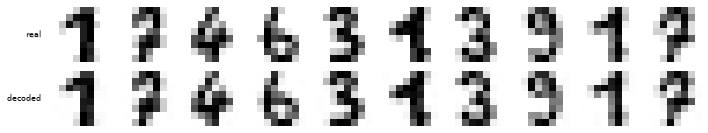

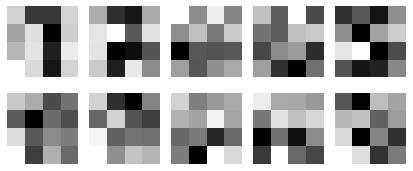

In [ ]:
show_rows([test_x[:10], rec_test[:10]], ["real", "decoded"])
print("the 10 digits above are real; below them the same digits after encode and decode (the latent has", Z[0].numel(), "numbers instead of", X[0].numel(), ")")
with torch.no_grad():
    zz = vae.encode(test_x[:5]).latent_dist.mean * SCALE
fig, ax = plt.subplots(2, 5, figsize=(6, 2.8))
for k in range(5):
    for ch in range(2):
        ax[ch, k].imshow(zz[k, ch].numpy(), cmap="gray"); ax[ch, k].axis("off")
plt.tight_layout(); plt.show()
print("rows: latent channel 1 and 2 of five test digits (4 x 4 positions each, scaled to spread 1). The diffusion model works on THESE.")

### Step 2: the denoising U-Net in latent space

The U-Net learns to predict the noise in noisy latents, with the prompt entering through cross-attention. For one example in ten the prompt is dropped so that guidance can be used later (topic 6). 2000 updates take a few minutes on a CPU.

In [ ]:
# ---- step 2: train a denoising U-Net on a set of grids (latents or pixels); the prompt of every example is the sentence for its digit
sched = DDIMScheduler(**SCHED_CFG)
def train_ldm(data, labels, channels, size, steps, seed=0):
    torch.manual_seed(seed)
    unet, te = make_unet(channels, size), TextEncoder()
    opt = torch.optim.Adam(list(unet.parameters()) + list(te.parameters()), 1e-3)
    sc = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    ids_all, empty = tokenize(PROMPTS), tokenize([""])
    for s in range(steps):
        i = torch.randint(0, len(data), (64,))
        z0, ids = data[i], ids_all[labels[i]].clone()
        ids[torch.rand(64) < 0.1] = empty[0]                # for 1 example in 10 the prompt is dropped (needed for guidance later)
        t = torch.randint(0, 1000, (64,))
        eps = torch.randn_like(z0)
        zt = sched.add_noise(z0, eps, t)                    # the closed form of topic 2, done by the scheduler
        loss = F.mse_loss(unet(zt, t, encoder_hidden_states=te(ids)).sample, eps)
        opt.zero_grad(); loss.backward(); opt.step(); sc.step()
    return unet, te

unet_l, te_l = train_ldm(Z * SCALE, train_y, 2, 4, 2000)
print('latent U-Net parameters:', count(unet_l), ' text encoder parameters:', count(te_l))

latent U-Net parameters: 786690  text encoder parameters: 2640


### Step 3: generate

The sampling loop of a latent diffusion pipeline: prompt to text vectors, then 20 times (U-Net, scheduler step) starting from pure noise in latent space, then the decoder. Guidance pushes the result toward the prompt: scale 1 is no push, higher is stronger (lesson 6 of topic 6 studies it).

In [ ]:
# ---- the sampling loop of a latent diffusion pipeline: prompt -> text vectors -> loop of (U-Net, scheduler step) -> grid
@torch.no_grad()
def generate(unet, te, shape, labels, scheduler, steps=20, guidance=1.0, seed=0):
    scheduler.set_timesteps(steps)
    g = torch.Generator().manual_seed(seed)
    z = torch.randn((len(labels),) + shape, generator=g) * scheduler.init_noise_sigma
    cond, uncond = te(tokenize([PROMPTS[l] for l in labels])), te(tokenize([""] * len(labels)))
    for t in scheduler.timesteps:
        zin = scheduler.scale_model_input(z, t)
        e_c = unet(zin, t, encoder_hidden_states=cond).sample
        if guidance != 1.0:                                 # classifier-free guidance: push away from the no-prompt guess (topic 6)
            e_u = unet(zin, t, encoder_hidden_states=uncond).sample
            e_c = e_u + guidance * (e_c - e_u)
        z = scheduler.step(e_c, t, z).prev_sample
    return z

labels300 = torch.arange(300) % 10                          # 30 pictures of every digit
def judge_report(name, imgs, labels=labels300):
    p = torch.tensor(judge.predict_proba(imgs.flatten(1).numpy()))
    print(f"{name:34s} judge confidence {p.max(1).values.mean():.3f}   picture shows the prompted digit {(p.argmax(1) == labels).float().mean():.3f}")
    return p.max(1).values.mean().item(), (p.argmax(1) == labels).float().mean().item()

latent diffusion, guidance 1.0     judge confidence 0.945   picture shows the prompted digit 0.937
latent diffusion, guidance 3.0     judge confidence 0.993   picture shows the prompted digit 0.990
latent diffusion, guidance 7.0     judge confidence 0.994   picture shows the prompted digit 0.997
real test digits (reference)       judge confidence 0.918   picture shows the prompted digit 0.919


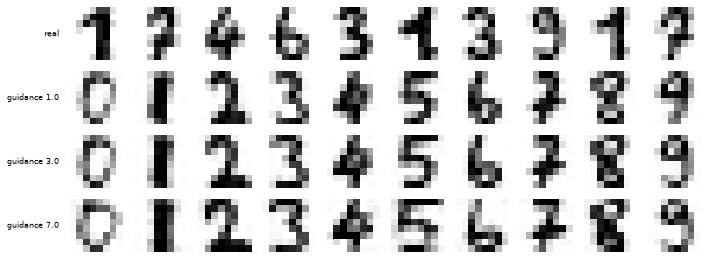

In [ ]:
prompts10 = ["a drawing of the digit " + n for n in VOC[8:]]
ids10 = torch.arange(10)
def decode(z):
    with torch.no_grad():
        return vae.decode(z / SCALE).sample.clamp(-1, 1)
rows, titles = [test_x[:10]], ["real"]
for g in (1.0, 3.0, 7.0):
    rows.append(decode(generate(unet_l, te_l, (2, 4, 4), ids10, DDIMScheduler(**SCHED_CFG), 20, g, seed=3)))
    titles.append(f"guidance {g}")
show_rows(rows, titles)
for g in (1.0, 3.0, 7.0):
    img = decode(generate(unet_l, te_l, (2, 4, 4), labels300, DDIMScheduler(**SCHED_CFG), 20, g))
    judge_report(f"latent diffusion, guidance {g}", img)
judge_report("real test digits (reference)", test_x, test_y)

### The pipeline as one object

The same parts and the same call order as a diffusers `StableDiffusionPipeline`, at toy size. The counts show where the work goes: the U-Net runs once per step and per guidance branch; the text encoder and the decoder run once.

calls for one run of the pipeline (20 steps, guidance 3.0): {'text_encoder': 2, 'unet': 40, 'vae_decoder': 1}
multiply-adds for ONE picture: text encoder 0.0%, U-Net loop 98.7%, decoder 1.3%


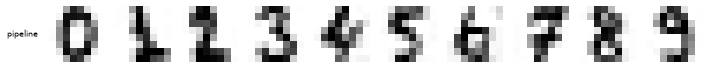

In [ ]:
class ToyPipeline:
    """the parts and the call order of a diffusers text-to-image pipeline, at toy size:
    tokenizer -> text encoder -> (U-Net, scheduler step) x steps -> autoencoder decoder"""
    def __init__(self, text_encoder, unet, vae, scale):
        self.text_encoder, self.unet, self.vae, self.scale = text_encoder, unet, vae, scale
        self.calls = {"text_encoder": 0, "unet": 0, "vae_decoder": 0}
    @torch.no_grad()
    def __call__(self, prompts, scheduler, num_inference_steps=20, guidance_scale=3.0, seed=0):
        n = len(prompts)
        cond = self.text_encoder(tokenize(prompts)); self.calls["text_encoder"] += 1                 # 1. the prompt becomes vectors
        uncond = self.text_encoder(tokenize([""] * n)); self.calls["text_encoder"] += 1              #    and so does the empty prompt (for guidance)
        scheduler.set_timesteps(num_inference_steps)
        z = torch.randn((n, 2, 4, 4), generator=torch.Generator().manual_seed(seed)) * scheduler.init_noise_sigma     # 2. start from pure noise in latent space
        for t in scheduler.timesteps:                                                                # 3. the denoising loop
            zin = scheduler.scale_model_input(z, t)
            e_u = self.unet(zin, t, encoder_hidden_states=uncond).sample
            e_c = self.unet(zin, t, encoder_hidden_states=cond).sample
            self.calls["unet"] += 2
            z = scheduler.step(e_u + guidance_scale * (e_c - e_u), t, z).prev_sample
        self.calls["vae_decoder"] += 1                                                               # 4. decode once
        return self.vae.decode(z / self.scale).sample.clamp(-1, 1)

from torch.utils.flop_counter import FlopCounterMode
def macs(fn):
    with FlopCounterMode(display=False) as fc:
        fn()
    return fc.get_total_flops() // 2
pipe = ToyPipeline(te_l, unet_l, vae, SCALE)
imgs = pipe(prompts10, DDIMScheduler(**SCHED_CFG), num_inference_steps=20, guidance_scale=3.0, seed=1)
show_rows([imgs], ["pipeline"])
print("calls for one run of the pipeline (20 steps, guidance 3.0):", pipe.calls)
m_te = macs(lambda: te_l(tokenize(["a drawing of the digit seven"])))
m_unet = macs(lambda: unet_l(torch.randn(1, 2, 4, 4), torch.tensor([10]), encoder_hidden_states=torch.randn(1, 8, 16)))
m_dec = macs(lambda: vae.decode(torch.randn(1, 2, 4, 4)))
total = 2 * m_te + 40 * m_unet + m_dec
print(f"multiply-adds for ONE picture: text encoder {100 * 2 * m_te / total:.1f}%, U-Net loop {100 * 40 * m_unet / total:.1f}%, decoder {100 * m_dec / total:.1f}%")

## 3. Schedulers: same model, different samplers

One trained network, several diffusers schedulers built from the same configuration. The reference is a 200-step DDIM run from the same noise; 'distance' is how far the final latent is from it.

scheduler                         steps  judge confidence  shows prompted digit  distance of the latent to the reference
DDIMScheduler                         5            0.962                 0.967                0.203
DDIMScheduler                        10            0.952                 0.947                0.109
DDIMScheduler                        20            0.945                 0.937                0.058
EulerDiscreteScheduler                5            0.936                 0.893                0.382
EulerDiscreteScheduler               10            0.940                 0.920                0.142
EulerDiscreteScheduler               20            0.941                 0.920                0.065
DPMSolverMultistepScheduler           5            0.953                 0.947                0.207
DPMSolverMultistepScheduler          10            0.941                 0.937                0.069
DPMSolverMultistepScheduler          20            0.937                 0.917 

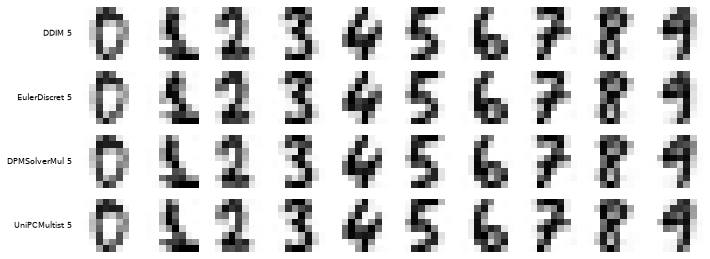

In [ ]:
from diffusers import (DDPMScheduler, EulerDiscreteScheduler, EulerAncestralDiscreteScheduler, DPMSolverMultistepScheduler, UniPCMultistepScheduler)
ref_z = generate(unet_l, te_l, (2, 4, 4), labels300, DDIMScheduler(**SCHED_CFG), 200, 1.0)       # a 200-step DDIM run from the same noise is the reference
print("scheduler                         steps  judge confidence  shows prompted digit  distance of the latent to the reference")
rows, titles = [], []
for cls in (DDIMScheduler, EulerDiscreteScheduler, DPMSolverMultistepScheduler, UniPCMultistepScheduler):
    for steps in (5, 10, 20):
        z = generate(unet_l, te_l, (2, 4, 4), labels300, cls.from_config(sched.config), steps, 1.0)
        img = decode(z)
        p = torch.tensor(judge.predict_proba(img.flatten(1).numpy()))
        print(f"{cls.__name__:33s} {steps:5d} {p.max(1).values.mean():16.3f} {(p.argmax(1) == labels300).float().mean():21.3f} {(z - ref_z).abs().mean():20.3f}")
        if steps == 5:
            rows.append(img[:10]); titles.append(cls.__name__.replace("Scheduler", "")[:12] + " 5")
show_rows(rows, titles)

### When the scheduler does not match the model

The network learned to remove noise of a particular schedule. A scheduler with another schedule tells it the wrong noise level at every step.

In [ ]:
# a scheduler whose noise schedule does NOT match the one the network was trained with
for name, kw in (("matching (linear 1e-4 .. 0.02)", {}), ("mismatch (scaled_linear 0.00085 .. 0.012)", dict(beta_schedule="scaled_linear", beta_start=0.00085, beta_end=0.012))):
    s = DDIMScheduler(**{**SCHED_CFG, **kw})
    z = generate(unet_l, te_l, (2, 4, 4), labels300, s, 20, 1.0)
    p = torch.tensor(judge.predict_proba(decode(z).flatten(1).numpy()))
    print(f"{name:44s} judge confidence {p.max(1).values.mean():.3f}   shows prompted digit {(p.argmax(1) == labels300).float().mean():.3f}   latent spread {z.std():.2f} (target 1.0)")

matching (linear 1e-4 .. 0.02)               judge confidence 0.945   shows prompted digit 0.937   latent spread 1.05 (target 1.0)
mismatch (scaled_linear 0.00085 .. 0.012)    judge confidence 0.871   shows prompted digit 0.870   latent spread 0.80 (target 1.0)


## 4. Your own prompts

vocabulary: ['<pad>', '<bos>', '<eos>', 'a', 'drawing', 'of', 'the', 'digit', 'zero', 'one', 'two', 'three', 'four', 'five', 'six', 'seven', 'eight', 'nine']


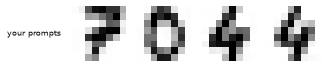

In [ ]:
# Your own prompts. The toy vocabulary has only these words; a word outside it cannot be tokenized (a real tokenizer splits unknown words into pieces).
print("vocabulary:", VOC)
mine = ["a drawing of the digit seven", "a drawing of the digit zero", "a drawing of the digit four", "a drawing of the digit four"]     # change me. The last two prompts are equal but start from different noise: two different fours
try:
    pipe_out = ToyPipeline(te_l, unet_l, vae, SCALE)(mine, DDIMScheduler(**SCHED_CFG), 20, 3.0, seed=7)
    show_rows([pipe_out], ["your prompts"])
except KeyError as e:
    print("this word is not in the toy vocabulary:", e)

## Try it yourself

1. In the photo autoencoder change `C = 4` to `1` and to `16` (and the matching number in the title). How do the three numbers (autoencoder, best linear code, shrink) move? Lesson 2 measured the same thing on the whole test photo.
2. Replace the test photo by your own (the commented lines in the first photo cell). Which details does the autoencoder lose first: edges, small text, faces, fine texture?
3. In the digit part change `range(2000)` of the U-Net training to `500` and to `4000`. How do the judge numbers and the pictures change?
4. Change the sampling steps from 20 to 5 in the first sample cell. Compare with the scheduler table.
5. Which scheduler gives the best picture at 5 steps in the table? Does that change with guidance 3 instead of 1 (change the `1.0` in the scheduler cell)?
6. Change the latent channels of the digit autoencoder (the `make_vae(2)` calls) to `4`: the latent grows. What happens to the U-Net's cost and to the quality?
7. Write two sentences for a colleague: what is in the latent, and what does the scheduler decide?